In [1]:
import pandas as pd
import numpy as np
import h5py
import IPython
import PIL
import matplotlib.pyplot as plt
import os
import io

import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F

In [2]:
# IMPORTANT:
#   Whenever you start a new colab runtime, use the following code to download
#   the training dataset onto the runtime local storage.
#   This should take ~3-5 mins for the whole dataset.
#   You can then load data from the local storage (/content/data) into your colab
#   notebook using the `h5py` library (see example below).
from huggingface_hub import hf_hub_download
hf_hub_download(repo_id="benmoseley/ese-dl-2025-26-group-project", filename="train.h5", repo_type="dataset", local_dir="data")
hf_hub_download(repo_id="benmoseley/ese-dl-2025-26-group-project", filename="events.csv", repo_type="dataset", local_dir="data")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


train.h5:   0%|          | 0.00/10.7G [00:00<?, ?B/s]

events.csv: 0.00B [00:00, ?B/s]

'data/events.csv'

In [3]:
# this DataFrame contains all of the event meta data
df = pd.read_csv("data/events.csv", parse_dates=["start_utc"])
df

,id,img_type,event_type,start_utc,llcrnrlat,llcrnrlon,urcrnrlat,urcrnrlon,proj,height_m,width_m
0,S778114,ir069,Hail,2018-08-20 19:50:00+00:00,32.781533,-92.631841,35.944590,-88.134075,+proj=laea +lat_0=38 +lon_0=-98 +units=m +a=63...,384000.0,384000.0
1,S778114,ir107,Hail,2018-08-20 19:50:00+00:00,32.781533,-92.631841,35.944590,-88.134075,+proj=laea +lat_0=38 +lon_0=-98 +units=m +a=63...,384000.0,384000.0
2,S778114,lght,Hail,NaT,32.781533,-92.631841,35.944590,-88.134075,+proj=laea +lat_0=38 +lon_0=-98 +units=m +a=63...,384000.0,384000.0
3,S778114,vil,Hail,2018-08-20 19:50:00+00:00,32.781533,-92.631841,35.944590,-88.134075,+proj=laea +lat_0=38 +lon_0=-98 +units=m +a=63...,384000.0,384000.0
4,S778114,vis,Hail,2018-08-20 19:50:00+00:00,32.781533,-92.631841,35.944590,-88.134075,+proj=laea +lat_0=38 +lon_0=-98 +units=m +a=63...,384000.0,384000.0
...,...,...,...,...,...,...,...,...,...,...,...
3995,S832818,ir069,Funnel Cloud,2019-07-28 17:44:00+00:00,46.493514,-100.371384,49.953392,-95.191216,+proj=laea +lat_0=38 +lon_0=-98 +units=m +a=63...,384000.0,384000.0
3996,S832818,ir107,Funnel Cloud,2019-07-28 17:44:00+00:00,46.493514,-100.371384,49.953392,-95.191216,+proj=laea +lat_0=38 +lon_0=-98 +units=m +a=63...,384000.0,384000.0
3997,S832818,lght,Funnel Cloud,NaT,46.493514,-100.371384,49.953392,-95.191216,+proj=laea +lat_0=38 +lon_0=-98 +units=m +a=63...,384000.0,384000.0
3998,S832818,vil,Funnel Cloud,2019-07-28 17:45:00+00:00,46.493514,-100.371384,49.953392,-95.191216,+proj=laea +lat_0=38 +lon_0=-98 +units=m +a=63...,384000.0,384000.0


In [4]:
# Filter IDs that have all 4 required modalities for Task 3
required_types = ['vis', 'ir069', 'ir107', 'vil']
df_pivot = df.pivot(index='id', columns='img_type', values='event_type')
ids = df_pivot.dropna(subset=required_types).index.tolist()
df_duplicate = df[df['id'].isin(ids)][['id', 'event_type']].drop_duplicates()

data preprocessing

In [5]:
def resize_images(img, target_size=(384, 384), interpolation=cv2.INTER_LINEAR):
    """
    Resize a single image to target size with proper dtype handling.
    Args:
        img: Input image (2D numpy array)
        target_size: Tuple of (height, width) for target size
            (default: (384, 384))
        interpolation: OpenCV interpolation method
            (default: cv2.INTER_LINEAR)
    Returns:
        Resized image with same dtype as input
    Raises:
        ValueError: If input is invalid or not a 2D array
        RuntimeError: If resizing fails
    """
    if img is None:
        raise ValueError("Input image cannot be None")
    if not isinstance(img, np.ndarray):
        raise ValueError(f"Input must be numpy array, got {type(img)}")
    if len(img.shape) != 2:
        raise ValueError(f"Expected 2D array (H, W), got shape {img.shape}")
    # Convert to float32 for proper interpolation
    # (cv2.resize works best with float32)
    # This handles int16, uint8, and other dtypes correctly
    original_dtype = img.dtype
    img_float = img.astype(np.float32)
    try:
        img_resized = cv2.resize(img_float, target_size,
                                 interpolation=interpolation)
        # Convert back to original dtype to preserve data type
        return img_resized.astype(original_dtype)
    except Exception as e:
        msg = (f"Error resizing image of shape {img.shape} "
               f"to {target_size}: {str(e)}")
        raise RuntimeError(msg)

In [6]:
def resize_all_events(all_events,
                      image_types_to_resize=['ir069', 'ir107'],
                      target_size=(384, 384),
                      interpolation=cv2.INTER_LINEAR):
    """
    Apply resizing to specified image types in all events.
    Args:
        all_events: Dictionary mapping event IDs to dictionaries of image data
        image_types_to_resize: List of image types to resize
            (default: ['ir069', 'ir107'])
        target_size: Tuple of (height, width) for target size
            (default: (384, 384))
        interpolation: OpenCV interpolation method
            (default: cv2.INTER_LINEAR)
    Returns:
        Dictionary with resized events
    Raises:
        ValueError: If input is invalid or data structure is unexpected
        RuntimeError: If resizing fails for any event
    """
    if all_events is None:
        raise ValueError("all_events cannot be None")
    if not isinstance(all_events, dict):
        msg = f"all_events must be a dictionary, got {type(all_events)}"
        raise ValueError(msg)
    if len(all_events) == 0:
        warnings.warn("all_events is empty, returning empty dictionary")
        return {}
    resized_events = {}
    for event_id, event in all_events.items():
        if event is None:
            warnings.warn(f"Event '{event_id}' is None, skipping")
            continue
        if not isinstance(event, dict):
            msg = (f"Event '{event_id}' must be a dictionary, "
                   f"got {type(event)}")
            raise ValueError(msg)
        resized_events[event_id] = {}
        for img_type, data in event.items():
            if img_type not in image_types_to_resize:
                # Copy data as-is for non-resized types
                resized_events[event_id][img_type] = data
                continue
            # Validate data
            if data is None:
                msg = (f"Data for '{img_type}' in event '{event_id}' "
                       f"is None, skipping")
                warnings.warn(msg)
                continue
            if not isinstance(data, np.ndarray):
                msg = (f"Expected numpy array for '{img_type}' "
                       f"in event '{event_id}', got {type(data)}")
                raise ValueError(msg)
            # Validate shape - must be 3D (H, W, T)
            if len(data.shape) != 3:
                msg = (f"Expected 3D array (H, W, T) for '{img_type}' "
                       f"in event '{event_id}', got shape {data.shape}. "
                       f"Only ir069 and ir107 should be resized.")
                raise ValueError(msg)
            H, W, T = data.shape
            # Validate dimensions are positive
            if H <= 0 or W <= 0 or T <= 0:
                msg = (f"Invalid dimensions for '{img_type}' "
                       f"in event '{event_id}': shape {data.shape} "
                       f"contains non-positive values")
                raise ValueError(msg)
            # Create output array with same dtype
            resized = np.zeros((target_size[0], target_size[1], T),
                               dtype=data.dtype)
            # Resize each time frame
            for t in range(T):
                try:
                    resized[:, :, t] = resize_images(
                        data[:, :, t],
                        target_size=target_size,
                        interpolation=interpolation
                    )
                except Exception as e:
                    msg = (f"Error resizing '{img_type}' in event "
                           f"'{event_id}' at time frame {t}: {str(e)}")
                    raise RuntimeError(msg)
            resized_events[event_id][img_type] = resized
    return resized_events

In [7]:
def augment_events(resized_events, df_duplicate,
                   flip_classes=['Funnel Cloud', 'Heavy Rain', 'Lightning'],
                   noise_classes=['Flash Flood', 'Flood', 'Funnel Cloud', 'Heavy Rain', 'Lightning', 'Tornado'],
                   noise_level=0.01):
    """
    Perform data augmentation for Task 3 events, including:
    1. Horizontal and vertical flips for minority classes.
    2. Gaussian noise perturbation for specified classes.

    Args:
        resized_events (dict): {event_id: {img_type: np.array(H, W, T)}}.
        df_duplicate (pd.DataFrame): Metadata with columns ['id', 'event_type'].
        flip_classes (list): Event types for flip augmentation.
        noise_classes (list): Event types for noise augmentation.
        noise_level (float): Relative scale of Gaussian noise.

    Returns:
        tuple: (augmented_events_dict, augmented_metadata_df)
    """
    augmented_events = resized_events.copy()
    new_rows = []

    # --- Step 1: Flip Augmentation ---
    minority_df = df_duplicate[df_duplicate['event_type'].isin(flip_classes)]
    print(f"Starting flip augmentation for classes: {flip_classes}")

    for _, row in minority_df.iterrows():
        old_id = row['id']
        etype = row['event_type']

        if old_id not in resized_events:
            continue

        # Horizontal flip
        aug_id_h = f"{old_id}_flip_h"
        augmented_events[aug_id_h] = {}
        for img_type, data in resized_events[old_id].items():
            augmented_events[aug_id_h][img_type] = np.flip(data, axis=1).copy()
        new_rows.append({'id': aug_id_h, 'event_type': etype})

        # Vertical flip
        aug_id_v = f"{old_id}_flip_v"
        augmented_events[aug_id_v] = {}
        for img_type, data in resized_events[old_id].items():
            augmented_events[aug_id_v][img_type] = np.flip(data, axis=0).copy()
        new_rows.append({'id': aug_id_v, 'event_type': etype})

    df_augmented = pd.concat([df_duplicate, pd.DataFrame(new_rows)], ignore_index=True)
    print(f"Flip augmentation complete! Added {len(new_rows)} samples.")

    # --- Step 2: Noise Augmentation ---
    new_events = {}
    new_rows_noise = []
    target_df = df_augmented[df_augmented['event_type'].isin(noise_classes)]
    print(f"Starting noise augmentation for classes: {noise_classes}")

    for _, row in target_df.iterrows():
        current_id = row['id']
        etype = row['event_type']

        if current_id not in augmented_events:
            continue

        noise_id = f"{current_id}_noise"
        new_events[noise_id] = {}

        for img_type, data in augmented_events[current_id].items():
            data_max = np.nanmax(np.abs(data))
            scale = noise_level * data_max if data_max > 0 else noise_level
            noise = np.random.normal(loc=0.0, scale=scale, size=data.shape).astype(np.float32)
            perturbed_data = np.clip(data + noise, np.nanmin(data), np.nanmax(data))
            new_events[noise_id][img_type] = perturbed_data.astype(data.dtype)

        new_rows_noise.append({'id': noise_id, 'event_type': etype})

    augmented_events.update(new_events)
    df_final = pd.concat([df_augmented, pd.DataFrame(new_rows_noise)], ignore_index=True)
    print(f"Noise augmentation complete! Added {len(new_rows_noise)} samples.")
    print(f"Final total sample count: {len(df_final)}")

    return augmented_events, df_final

In [8]:
# Memory-efficient processing
def process_events_memory_efficient(file_format=['vis', 'ir069', 'ir107', 'vil'],
                                    filepath='data/train.h5',
                                    image_types_to_resize=['ir069', 'ir107'],
                                    target_size=(384, 384),
                                    interpolation=cv2.INTER_LINEAR):
    """
    Process events one at a time to minimize memory usage.

    This generator function loads and processes one event at a time,
    preventing memory overflow for large datasets.

    Args:
        file_format: List of image types to load
        filepath: Path to the HDF5 file
        image_types_to_resize: List of image types to resize
        target_size: Target size for resizing
        interpolation: Interpolation method

    Yields:
        Tuple of (event_id, resized_event_dict) for each processed event
    """
    try:
        with h5py.File(filepath, 'r') as f:
            for event_id in f.keys():
                # Load only one event at a time
                event = {}
                for img_type in file_format:
                    if img_type not in f[event_id]:
                        continue
                    event[img_type] = f[event_id][img_type][:]

                # Process this single event
                single_event_dict = {event_id: event}
                resized = resize_all_events(single_event_dict,
                                            image_types_to_resize,
                                            target_size,
                                            interpolation)

                # Yield the result and free memory
                yield event_id, resized[event_id]

                # Explicitly delete to free memory
                del event, resized, single_event_dict

    except FileNotFoundError:
        raise FileNotFoundError(f"Could not find file: {filepath}")
    except Exception as e:
        raise RuntimeError(f"Error processing events: {str(e)}")


In [9]:
all_events_resized = {}
for event_id, resized_event in process_events_memory_efficient():
    all_events_resized[event_id] = resized_event
    if len(all_events_resized) % 100 == 0:
        print(f"Processed {len(all_events_resized)} events...")

print(f"Total events processed: {len(all_events_resized)}")

Processed 100 events...
Processed 200 events...
Processed 300 events...
Processed 400 events...
Processed 500 events...
Processed 600 events...
Processed 700 events...
Processed 800 events...
Total events processed: 800


In [10]:
all_events_aug, df_aug = augment_events(all_events_resized, df_duplicate)

Starting flip augmentation for classes: ['Funnel Cloud', 'Heavy Rain', 'Lightning']
Flip augmentation complete! Added 112 samples.
Starting noise augmentation for classes: ['Flash Flood', 'Flood', 'Funnel Cloud', 'Heavy Rain', 'Lightning', 'Tornado']
Noise augmentation complete! Added 393 samples.
Final total sample count: 1305


/tmp/ipython-input-3153703875.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


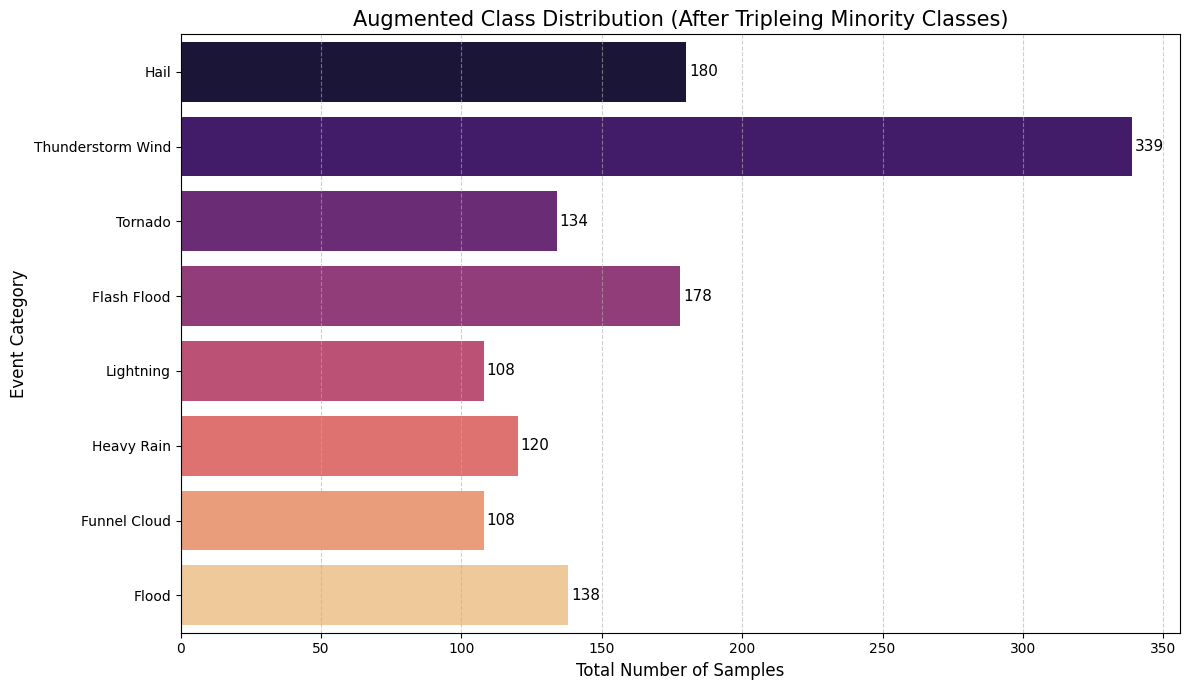

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prepare data for plotting
plt.figure(figsize=(12, 7))

# 2. Create the countplot
ax = sns.countplot(
    data=df_aug,
    y='event_type',
    order=df_aug['event_type'].unique().tolist(),
    palette='magma' # Changed palette to differentiate from the original plot
)

plt.title("Augmented Class Distribution (After Tripleing Minority Classes)", fontsize=15)
plt.xlabel("Total Number of Samples", fontsize=12)
plt.ylabel("Event Category", fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

# 3. Add exact counts on the bars for your report/presentation
for p in ax.patches:
    width = p.get_width()
    ax.text(
        width + 1,
        p.get_y() + p.get_height() / 2,
        f'{int(width)}',
        ha='left',
        va='center',
        fontsize=11
    )

plt.tight_layout()
plt.show()



In [12]:
len(all_events_resized)

800

In [13]:
all_events_resized['S767475']

{'vis': array([[[ 393,  398,  400, ...,   57,   59,   19],
         [ 387,  404,  382, ...,   44,   39,   27],
         [ 380,  387,  404, ...,   54,   35,   20],
         ...,
         [4082, 3416, 2737, ...,    9,   10,    7],
         [4423, 3694, 2866, ...,   14,    4,    8],
         [4470, 3863, 2986, ...,   21,   11,   -5]],
 
        [[ 374,  378,  374, ...,   52,   41,   31],
         [ 383,  394,  391, ...,   49,   54,   20],
         [ 393,  389,  393, ...,   43,   36,   20],
         ...,
         [4183, 3450, 3025, ...,   21,   13,    3],
         [4253, 3786, 3240, ...,   12,    8,    3],
         [4382, 3920, 3336, ...,   22,    7,    1]],
 
        [[ 378,  395,  389, ...,   44,   38,   16],
         [ 394,  393,  385, ...,   56,   37,   15],
         [ 395,  404,  383, ...,   49,   29,   14],
         ...,
         [4044, 3562, 3074, ...,   28,   17,    4],
         [4105, 3813, 3270, ...,   15,   15,    1],
         [4290, 3881, 3438, ...,   16,   12,    1]],
 
      

In [14]:
all_events_resized['S767475']['ir069']

array([[[-2335, -2361, -2341, ..., -2938, -2846, -2969],
        [-2330, -2358, -2340, ..., -2940, -2834, -2941],
        [-2320, -2354, -2338, ..., -2944, -2811, -2886],
        ...,
        [-4598, -4484, -4381, ..., -3763, -3774, -3819],
        [-4732, -4602, -4479, ..., -3847, -3824, -3869],
        [-4799, -4661, -4528, ..., -3890, -3849, -3894]],

       [[-2336, -2357, -2335, ..., -2955, -2861, -2985],
        [-2331, -2355, -2335, ..., -2956, -2854, -2957],
        [-2321, -2351, -2334, ..., -2959, -2838, -2901],
        ...,
        [-4681, -4531, -4410, ..., -3762, -3752, -3792],
        [-4795, -4643, -4506, ..., -3852, -3810, -3850],
        [-4851, -4699, -4553, ..., -3897, -3839, -3879]],

       [[-2338, -2349, -2324, ..., -2990, -2893, -3017],
        [-2333, -2347, -2325, ..., -2990, -2893, -2989],
        [-2321, -2345, -2327, ..., -2989, -2892, -2932],
        ...,
        [-4847, -4627, -4469, ..., -3761, -3709, -3739],
        [-4920, -4727, -4560, ..., -3862, -37

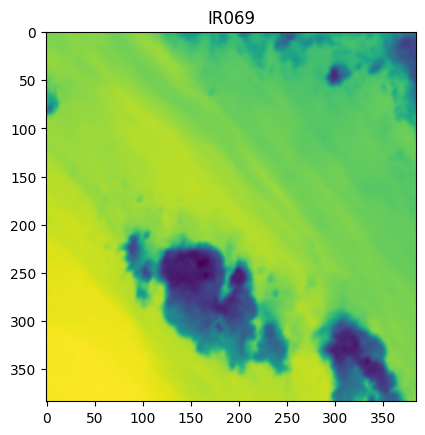

In [15]:
import matplotlib.pyplot as plt

img = all_events_resized['S767475']['ir069'][:,:,0]

plt.imshow(img, cmap='viridis')
plt.title('IR069')
plt.show()

In [16]:
all_events_resized['S767475']['ir069'][:,:,0].shape

(384, 384)